# Dataset Overview - `bench2_*`

What the benchmark data looks like, and whether it is what the configs asked for.

The radar is matched to the **CARRADA** dataset so simulated and real range-Doppler maps are
directly comparable - see `docs/radar_config_carrada.md`.

Run top to bottom. Nothing here modifies data.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from radar.config import RadarConfig, derive_radar_params
from radar.simulator import make_axes

CFG = RadarConfig()
DERIVED = derive_radar_params(CFG)
_, _, RANGE_AXIS, VEL_AXIS = make_axes(CFG)

SPLITS = ["bench2_train", "bench2_val", "bench2_test", "bench2_tune", "bench2_snr_sweep"]
MAIN = ["bench2_train", "bench2_val", "bench2_test"]
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SPLIT_COLOR = {"bench2_train": BLUE, "bench2_val": ORANGE, "bench2_test": AQUA}

plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": "#c3c2b7", "grid.color": GRID,
                     "text.color": INK, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10})


def tidy(ax):
    ax.grid(axis="y", linewidth=0.8)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)


print("ready")

ready


## 1. The radar

These values reproduce CARRADA's RD bin geometry, which is what makes a target look the same in simulation and in real data.

In [2]:
rows = [
    ("Carrier frequency", f"{CFG.fc/1e9:g} GHz"),
    ("Bandwidth", f"{CFG.B/1e6:g} MHz"),
    ("Chirp duration", f"{CFG.Tc*1e6:g} us"),
    ("Samples per chirp (N)", CFG.N),
    ("Chirps per frame (M)", CFG.M),
    ("--- derived ---", ""),
    ("Range resolution", f"{DERIVED.range_res:.4f} m"),
    ("Max range", f"{DERIVED.range_max:.2f} m"),
    ("Velocity resolution", f"{DERIVED.vel_res:.4f} m/s"),
    ("Max velocity", f"+/-{DERIVED.vel_max:.2f} m/s"),
    ("Sampling frequency", f"{DERIVED.fs/1e6:.4f} MHz"),
    ("Frame time", f"{CFG.M*CFG.Tc*1e3:.3f} ms"),
    ("RD map", f"{CFG.N//2} x {CFG.M}"),
]
print(pd.DataFrame(rows, columns=["parameter", "value"]).to_string(index=False))

            parameter        value
    Carrier frequency       77 GHz
            Bandwidth      768 MHz
       Chirp duration      72.4 us
Samples per chirp (N)          512
 Chirps per frame (M)           64
      --- derived ---             
     Range resolution     0.1952 m
            Max range      49.97 m
  Velocity resolution   0.4201 m/s
         Max velocity +/-13.44 m/s
   Sampling frequency   7.0718 MHz
           Frame time     4.634 ms
               RD map     256 x 64


## 2. The splits

Five datasets, all generated with **different seeds**. `bench2_test` is the only one that produces
reported numbers, and it is touched once.

`bench2_tune` chose the CFAR window. Having a separate split for that is why the geometry was never
selected on data the detectors are later scored on.

In [3]:
def load_meta(split):
    m = pd.read_csv(ROOT / "data" / split / "metadata.csv")
    m["split"] = split
    return m

meta = pd.concat([load_meta(s) for s in SPLITS], ignore_index=True)

summary = (meta.groupby("split")
           .agg(frames=("frame_id", "size"),
                targets=("num_targets", "sum"),
                mean_targets=("num_targets", "mean"))
           .reindex(SPLITS).round(2))
summary["role"] = ["network training", "overfitting check", "REPORTED NUMBERS",
                   "CFAR geometry (used)", "Pd-vs-SNR diagnostic"]
print(summary.to_string())

                  frames  targets  mean_targets                  role
split                                                                
bench2_train        8400    16122          1.92      network training
bench2_val          1600     3115          1.95     overfitting check
bench2_test         3200     6163          1.93      REPORTED NUMBERS
bench2_tune          400      787          1.97  CFAR geometry (used)
bench2_snr_sweep    1300     1300          1.00  Pd-vs-SNR diagnostic


## 3. Strata

Counts are exact, not approximate - the generator cycles through the named conditions.

`unresolved` is absent from **train** on purpose: every method hits the physics cap there, so there
is nothing to learn from it. It stays in val and test as a sanity check, since a score above ~0.5
there means something is broken.

In [4]:
counts = (meta[meta.split != "bench2_snr_sweep"]
          .pivot_table(index="condition", columns="split", values="frame_id",
                       aggfunc="size", fill_value=0))
counts = counts[["bench2_train", "bench2_val", "bench2_test", "bench2_tune"]]
print(counts.to_string())

split         bench2_train  bench2_val  bench2_test  bench2_tune
condition                                                       
clutter               1200         200          400           50
clutter_edge          1200         200          400           50
isolated              1200         200          400           50
masking               1200         200          400           50
mixed                 1200         200          400           50
multi                 1200         200          400           50
noise                 1200         200          400           50
unresolved               0         200          400           50


## 4. Loading target-level properties

Frame metadata gives scene-level facts; the per-target values (cell SNR, range, velocity, and the
swept clutter parameters) live in each frame's `labels.csv`.

Sampled rather than exhaustive so the notebook stays quick - 1,200 frames per split is far more
than enough to characterise a distribution.

In [5]:
def targets_of(split, n_sample=1600, seed=0):
    """Target-level rows for a split, from a RANDOM sample of frames.

    Random, not evenly spaced. The generator assigns conditions cyclically (frame i gets
    condition i % n_strata), so an evenly-spaced sample aliases against that cycle and can
    miss whole strata - a linspace sample of bench2_test returned 2 `unresolved` targets
    against 155-576 for every other condition.
    """
    fds = sorted((ROOT / "data" / split / "frames").iterdir())
    if n_sample and n_sample < len(fds):
        idx = np.random.default_rng(seed).choice(len(fds), n_sample, replace=False)
        fds = [fds[i] for i in sorted(idx)]

    rows = []
    for fd in fds:
        p = fd / "labels.csv"
        if p.stat().st_size <= 5:
            continue
        lab = pd.read_csv(p)
        m = json.loads((fd / "metadata.json").read_text(encoding="utf-8"))
        cl = m.get("clutter", {})
        lab["condition"] = m.get("condition", "sweep")
        lab["frame"] = fd.name
        lab["split"] = split
        lab["clutter_cnr"] = cl.get("cnr_db") if cl.get("enabled") else np.nan
        lab["clutter_shape"] = cl.get("shape") if cl.get("enabled") else np.nan
        rows.append(lab)
    return pd.concat(rows, ignore_index=True)


TARGETS = pd.concat([targets_of(s) for s in MAIN], ignore_index=True)
T = TARGETS[TARGETS.split == "bench2_test"]
print(TARGETS.groupby("split").size().to_string(), "\n\n(sampled targets per split)")

split
bench2_test     3112
bench2_train    3147
bench2_val      3115 

(sampled targets per split)


## 5. Are train / val / test identically distributed?

They should be. The three configs are identical apart from `random_seed` and frame count, so any
systematic difference would mean the generator is not doing what it claims - and a val split that
is easier or harder than train would silently mislead the early-stopping decision.

Overlaid as **densities**, since the splits differ in size.

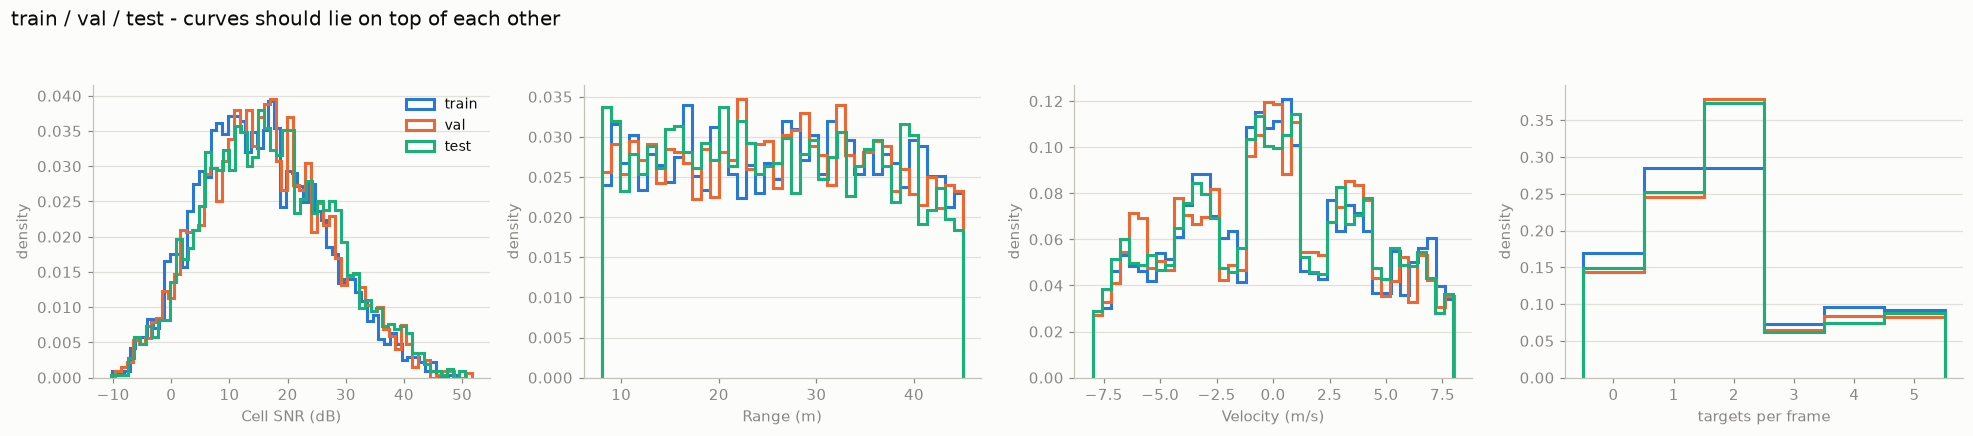

In [6]:
fields = [("cell_snr_db", "Cell SNR (dB)", 60),
          ("range_m", "Range (m)", 40),
          ("velocity_mps", "Velocity (m/s)", 40)]

fig, axes = plt.subplots(1, 4, figsize=(18, 4), dpi=110)
for ax, (col, label, bins) in zip(axes, fields):
    for s in MAIN:
        v = TARGETS.loc[TARGETS.split == s, col]
        ax.hist(v, bins=bins, density=True, histtype="step", linewidth=2,
                color=SPLIT_COLOR[s], label=s.replace("bench2_", ""))
    ax.set_xlabel(label)
    ax.set_ylabel("density")
    tidy(ax)

ax = axes[3]
for s in MAIN:
    v = meta.loc[meta.split == s, "num_targets"]
    ax.hist(v, bins=np.arange(-0.5, 6.5), density=True, histtype="step", linewidth=2,
            color=SPLIT_COLOR[s], label=s.replace("bench2_", ""))
ax.set_xlabel("targets per frame")
ax.set_ylabel("density")
tidy(ax)
axes[0].legend(frameon=False, fontsize=9)

fig.suptitle("train / val / test - curves should lie on top of each other",
             x=0.006, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.93));

### The same thing as numbers

In [7]:
stats = (TARGETS.groupby("split")
         .agg(targets=("cell_snr_db", "size"),
              snr_median=("cell_snr_db", "median"),
              snr_p10=("cell_snr_db", lambda v: np.percentile(v, 10)),
              snr_p90=("cell_snr_db", lambda v: np.percentile(v, 90)),
              range_mean=("range_m", "mean"),
              vel_absmean=("velocity_mps", lambda v: v.abs().mean()))
         .reindex(MAIN).round(2))
stats["frames"] = [len(meta[meta.split == s]) for s in MAIN]
stats["mean_targets"] = [meta.loc[meta.split == s, "num_targets"].mean().round(3) for s in MAIN]
print(stats.to_string())
print()
print("max spread between splits:")
for c in ("snr_median", "snr_p10", "snr_p90", "range_mean", "vel_absmean"):
    print(f"  {c:<14}{stats[c].max() - stats[c].min():.3f}")

              targets snr_median  snr_p10  snr_p90 range_mean  vel_absmean  frames  mean_targets
split                                                                                           
bench2_train     3147  14.776646     2.35    29.93  26.354211         3.33    8400         1.919
bench2_val       3115  15.878099     2.70    31.17  26.177812         3.36    1600         1.947
bench2_test      3112  16.405824     3.20    31.51  25.779564         3.39    3200         1.926

max spread between splits:
  snr_median    1.629
  snr_p10       0.850
  snr_p90       1.580
  range_mean    0.575
  vel_absmean   0.060


## 6. Properties by scenario

Each stratum is a deliberately different scene, so these should *not* match each other - the table
below is a check that each one contains what its config specified.

Note `clutter`, `clutter_edge` and `mixed` are the only strata with clutter enabled, and that
`clutter_edge` velocities sit clear of the ridge while `clutter` velocities sit inside it.

In [8]:
per_frame = meta[meta.split.isin(MAIN)].groupby(["split", "condition"]).num_targets.mean()

by_scen = (T.groupby("condition")
           .agg(targets=("cell_snr_db", "size"),
                snr_median=("cell_snr_db", "median"),
                snr_min=("cell_snr_db", "min"),
                snr_max=("cell_snr_db", "max"),
                range_min=("range_m", "min"),
                range_max=("range_m", "max"),
                absvel_min=("velocity_mps", lambda v: v.abs().min()),
                absvel_max=("velocity_mps", lambda v: v.abs().max()),
                clutter=("clutter_cnr", lambda v: f"{100*v.notna().mean():.0f}%"))
           .round(2))
by_scen["tgt/frame"] = [round(per_frame.get(("bench2_test", c), np.nan), 2)
                        for c in by_scen.index]
print(by_scen.to_string())

              targets snr_median    snr_min    snr_max range_min  range_max  absvel_min  absvel_max clutter  tgt/frame
condition                                                                                                             
clutter           407  15.099999  -4.932034  44.638779  8.039923  44.961821        0.01        1.20    100%       2.01
clutter_edge      280  14.581028  -5.867347   40.27633  8.063156  44.821576        2.50        4.20    100%       1.48
isolated          193  13.750714  -5.587662  40.626849  8.064628  44.937871        0.03        7.90      0%       1.00
masking           406  18.727434 -10.403615  50.500468  8.105564  41.795974        0.04        7.06      0%       2.00
mixed             495   14.13431  -9.039169   46.53401  8.050035  44.996665        0.03        7.99    100%       2.38
multi             943  15.042045  -8.218127  45.940125  8.049516  44.954053        0.00        8.00      0%       4.54
unresolved        388  23.904023    4.85923  49.

### Difficulty per scenario

Cell SNR is the difficulty dial. The strata deliberately differ: `multi` and `mixed` inherit the default range law, while the paired strata (`masking`, `unresolved`) carry an explicit strong/weak amplitude split.

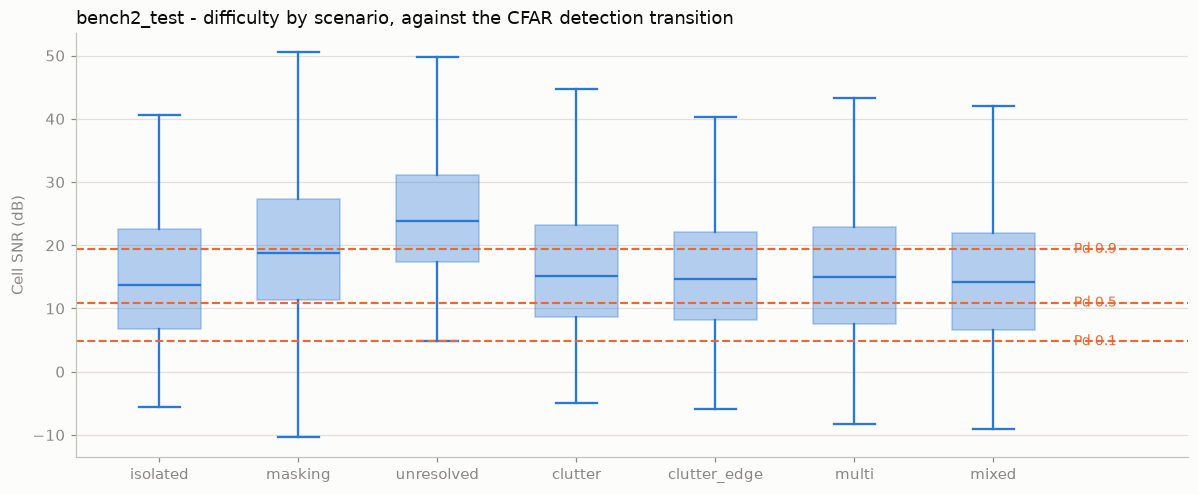

In [9]:
order = [c for c in ["isolated", "masking", "unresolved", "clutter",
                      "clutter_edge", "multi", "mixed"] if c in set(T.condition)]
data = [T.loc[T.condition == c, "cell_snr_db"].values for c in order]

fig, ax = plt.subplots(figsize=(11, 4.6), dpi=110)
# Tick labels set separately: boxplot's `labels=` was renamed to `tick_labels=` in
# matplotlib 3.9, so passing either directly breaks on one version or the other.
bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6)
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels(order)
for patch in bp["boxes"]:
    patch.set_facecolor(BLUE)
    patch.set_alpha(0.35)
    patch.set_edgecolor(BLUE)
for part in ("whiskers", "caps", "medians"):
    for line in bp[part]:
        line.set_color(BLUE)
        line.set_linewidth(1.5)

for y, lab in ((4.8, "Pd 0.1"), (10.9, "Pd 0.5"), (19.4, "Pd 0.9")):
    ax.axhline(y, color=ORANGE, ls="--", lw=1.4)
    ax.text(len(order) + 0.55, y, f" {lab}", color=ORANGE, fontsize=9, va="center")

ax.set_ylabel("Cell SNR (dB)")
ax.set_title("bench2_test - difficulty by scenario, against the CFAR detection transition",
             loc="left", fontsize=12)
ax.set_xlim(0.4, len(order) + 1.4)
tidy(ax)
fig.tight_layout();

## 7. What a frame contains

`rd_map_mag.npy` discards phase. The proposal requires an ablation comparing **magnitude vs I/Q
input**, so the complex map is kept as well - otherwise that experiment would have needed a third
full regeneration.

In [10]:
fd = sorted((ROOT / "data" / "bench2_test" / "frames").iterdir())[0]
for f in sorted(fd.iterdir()):
    print(f"  {f.name:<24}{f.stat().st_size/1024:8.1f} KB")

print()
print("labels.csv columns:", list(pd.read_csv(fd / "labels.csv").columns))
print()
print("metadata keys:", list(json.loads((fd / "metadata.json").read_text(encoding="utf-8"))))

  label_mask.npy              16.1 KB
  labels.csv                   0.2 KB
  metadata.json                1.5 KB
  rd_map_complex.npy         128.1 KB
  rd_map_mag.npy              64.1 KB

labels.csv columns: ['target_id', 'range_m', 'velocity_mps', 'amplitude_db', 'range_bin', 'velocity_bin', 'nearest_range_m', 'nearest_velocity_mps', 'cell_snr_db']

metadata keys: ['scenario', 'condition', 'reference_cell_snr_db', 'snr_db', 'noise_var', 'snr_processing_gain_db', 'seed', 'radar_config', 'derived', 'rd_shape', 'num_targets', 'targets', 'clutter', 'multipath', 'compact', 'files']


## 8. One frame per stratum

Brightness is **dB above that frame's own noise floor**, not below the map maximum. Peak
normalisation hides everything, because a target near the detection threshold sits only a few dB
above the brightest noise.

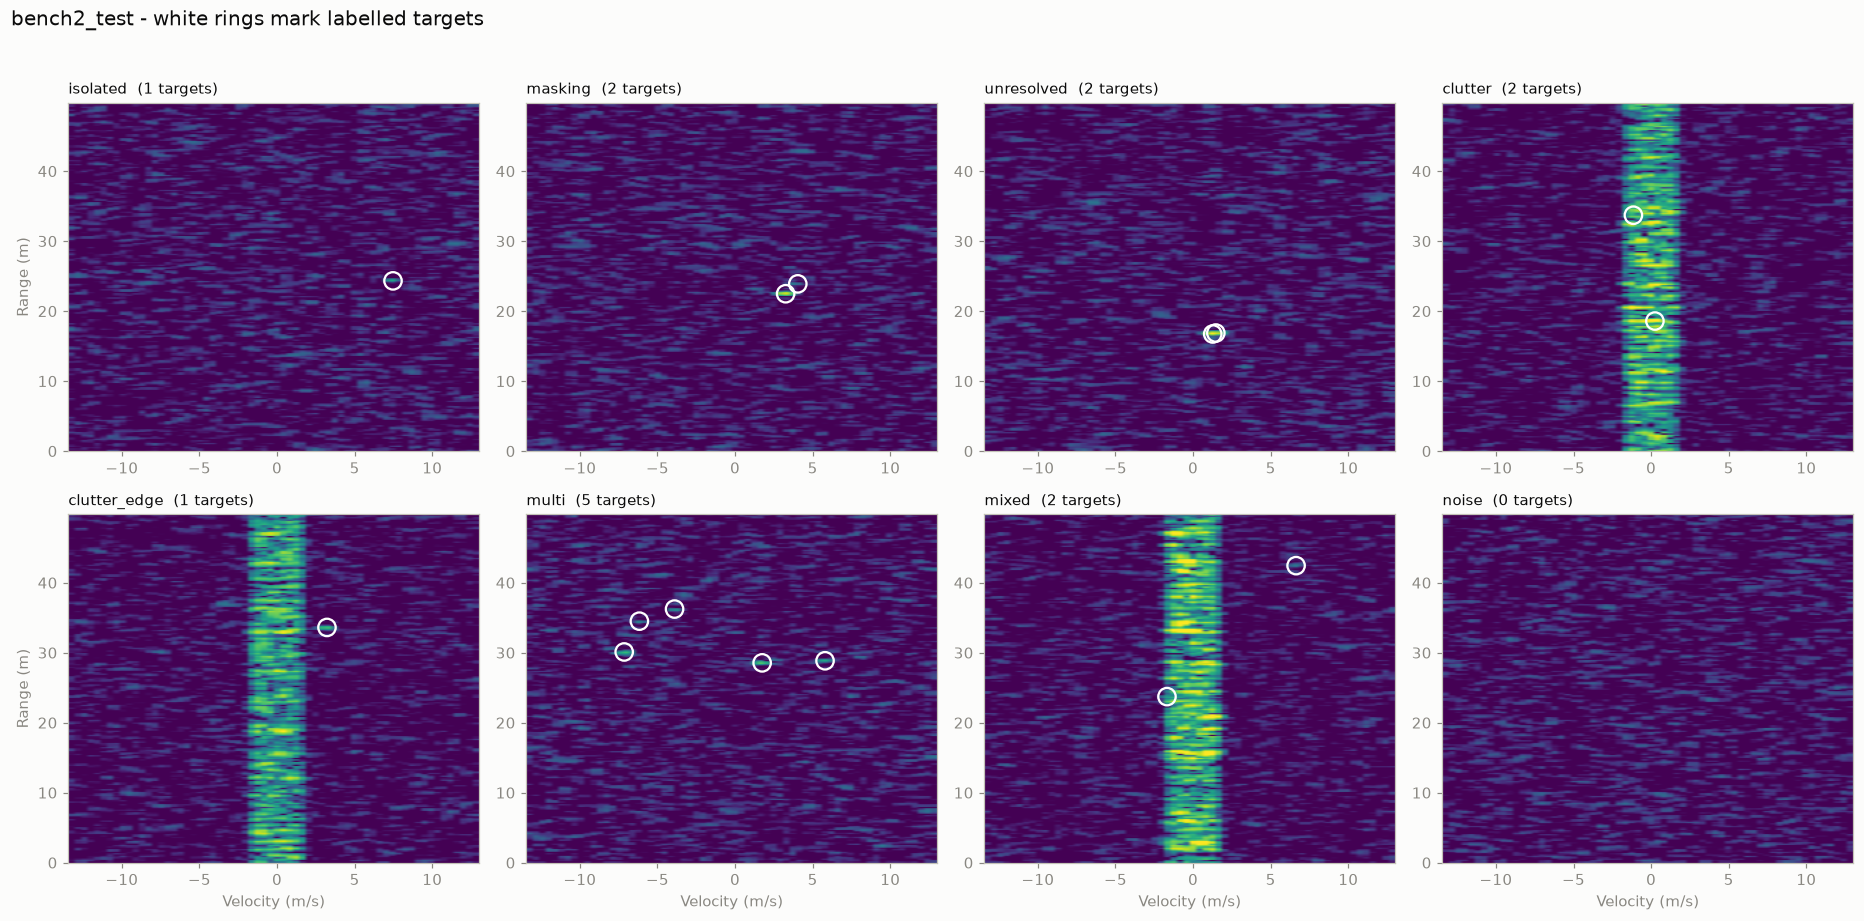

In [11]:
def pick(split, cond):
    """First frame of a condition, preferring a typical target count for that condition.

    A blanket "num_targets <= 3" filter would return nothing for `multi`, which carries 4-5 by
    design, so the preference is relative to what the condition actually contains.
    """
    frames = []
    for fd in sorted((ROOT / "data" / split / "frames").iterdir()):
        m = json.loads((fd / "metadata.json").read_text(encoding="utf-8"))
        if m.get("condition") == cond:
            frames.append((m.get("num_targets", 0), fd))
    if not frames:
        return None
    typical = int(np.median([n for n, _ in frames]))
    return min(frames, key=lambda t: abs(t[0] - typical))[1]


ORDER = ["isolated", "masking", "unresolved", "clutter",
         "clutter_edge", "multi", "mixed", "noise"]
ext = [VEL_AXIS[0], VEL_AXIS[-1], RANGE_AXIS[0], RANGE_AXIS[-1]]

fig, axes = plt.subplots(2, 4, figsize=(17, 8.5), dpi=110)
for ax, cond in zip(axes.ravel(), ORDER):
    fd = pick("bench2_test", cond)
    mag = np.load(fd / "rd_map_mag.npy")
    db = 10 * np.log10(mag**2 / np.median(mag**2) + 1e-12)
    ax.imshow(db, aspect="auto", origin="lower", cmap="viridis",
              vmin=0, vmax=30, extent=ext)
    p = fd / "labels.csv"
    lab = pd.read_csv(p) if p.stat().st_size > 5 else pd.DataFrame()
    if len(lab):
        ax.scatter(lab.velocity_mps, lab.range_m, s=130, facecolors="none",
                   edgecolors="white", linewidths=1.5)
    ax.set_title(f"{cond}  ({len(lab)} targets)", loc="left", fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("Range (m)")
for ax in axes[-1, :]:
    ax.set_xlabel("Velocity (m/s)")
fig.suptitle("bench2_test - white rings mark labelled targets", x=0.006, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.96));

## 9. Difficulty overall

Cell SNR is measured **per target** from a clean map rather than assumed from the request - so it
captures scalloping and the radar-equation range law.

The CFAR detection transition at Pfa 1e-4 runs from about **4.8 dB** (Pd 0.1) through **10.9 dB**
(Pd 0.5) to **19.4 dB** (Pd 0.9). Most targets should sit inside that band; targets far above it are
found by every method and discriminate nothing.

median 16.4 dB   below 5 dB 13.9%   above 30 dB 12.3%


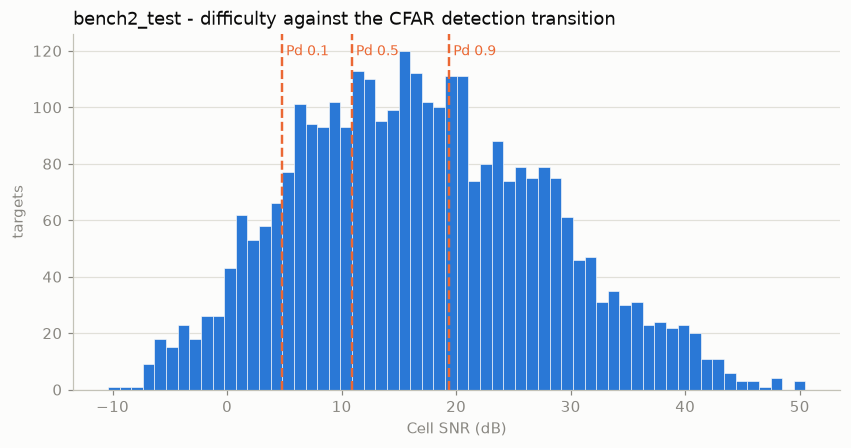

In [12]:
s = T.cell_snr_db.values

fig, ax = plt.subplots(figsize=(9, 4.2), dpi=110)
ax.hist(s, bins=60, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
for x, lab in ((4.8, "Pd 0.1"), (10.9, "Pd 0.5"), (19.4, "Pd 0.9")):
    ax.axvline(x, color=ORANGE, linewidth=1.6, linestyle="--")
    ax.text(x, ax.get_ylim()[1]*0.94, f" {lab}", color=ORANGE, fontsize=9)
ax.set_xlabel("Cell SNR (dB)")
ax.set_ylabel("targets")
ax.set_title("bench2_test - difficulty against the CFAR detection transition",
             loc="left", fontsize=12)
tidy(ax)

print(f"median {np.median(s):.1f} dB   below 5 dB {100*np.mean(s<5):.1f}%   "
      f"above 30 dB {100*np.mean(s>=30):.1f}%")

## 10. The swept parameters

Two quantities are drawn per frame and recorded rather than fixed. That turns them into measured
variables, so the analyses come from grouping results afterwards instead of from separate
experiments:

* **target separation** in `masking` - gives the proposal's close-target ablation, and lets the
  resolution limit emerge from data instead of being asserted
* **clutter severity and tail shape** - CFAR's threshold assumes exponentially distributed cell
  power, so this measures how fast the false-alarm rate drifts as clutter gets spikier

separation    0.41 - 2.49 m
clutter CNR   5.2 - 25.0 dB
Weibull shape 1.10 - 2.00


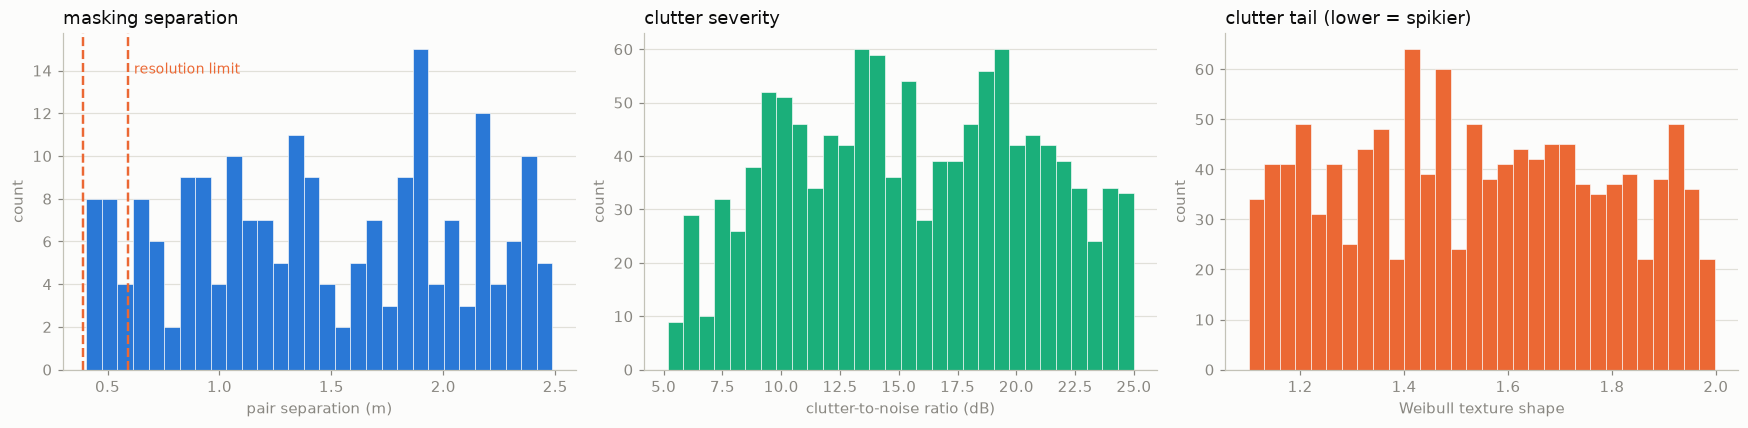

In [13]:
mask = T[T.condition == "masking"]
sep = mask.groupby("frame").range_m.apply(lambda g: abs(g.max() - g.min()))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), dpi=110)
axes[0].hist(sep, bins=30, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
for x in (0.39, 0.59):
    axes[0].axvline(x, color=ORANGE, ls="--", lw=1.6)
axes[0].text(0.60, axes[0].get_ylim()[1]*0.88, " resolution limit", color=ORANGE, fontsize=9)
axes[0].set_xlabel("pair separation (m)")
axes[0].set_title("masking separation", loc="left")

cl = T.dropna(subset=["clutter_cnr"])
axes[1].hist(cl.clutter_cnr, bins=30, color=AQUA, edgecolor=SURFACE, linewidth=0.4)
axes[1].set_xlabel("clutter-to-noise ratio (dB)")
axes[1].set_title("clutter severity", loc="left")
axes[2].hist(cl.clutter_shape, bins=30, color=ORANGE, edgecolor=SURFACE, linewidth=0.4)
axes[2].set_xlabel("Weibull texture shape")
axes[2].set_title("clutter tail (lower = spikier)", loc="left")
for ax in axes:
    ax.set_ylabel("count")
    tidy(ax)
fig.tight_layout()

print(f"separation    {sep.min():.2f} - {sep.max():.2f} m")
print(f"clutter CNR   {cl.clutter_cnr.min():.1f} - {cl.clutter_cnr.max():.1f} dB")
print(f"Weibull shape {cl.clutter_shape.min():.2f} - {cl.clutter_shape.max():.2f}")

## 11. Class balance

What the loss sees. Plain cross-entropy would collapse to predicting all-zeros and still score over
99.8% "accuracy", which is why the loss is weighted and why the ROC, not accuracy, is the metric.

In [14]:
for split in MAIN:
    fds = sorted((ROOT / "data" / split / "frames").iterdir())
    idx = np.random.default_rng(0).choice(len(fds), 150, replace=False)
    pos = tot = 0
    for i in idx:
        m = np.load(fds[i] / "label_mask.npy")
        pos += int(m.sum())
        tot += m.size
    print(f"{split:<20}positive rate {pos/tot:.6f}   ->  1 : {int(tot/pos)}")

bench2_train        positive rate 0.001021   ->  1 : 979


bench2_val          positive rate 0.001007   ->  1 : 992


bench2_test         positive rate 0.000981   ->  1 : 1019


## 12. Verification status

Full gates: `scripts/verify_splits.py` (is anything broken?) and `scripts/audit_datasets.py` (is it
what we asked for?).

| check | result |
|---|---|
| Balanced strata | pass |
| **Leakage between splits** | **zero shared frames**, checked by content hash rather than by seed |
| Label alignment | 92.3-93.6%; **100%** on isolated, multi and the SNR sweep |
| Targets in the untested border | zero |
| Non-finite values | zero |
| Every stratum matches its config | all eight |
| Label bins vs physical coordinates | 1047/1047 |

Alignment is not 100% overall, and that is correct. It falls only where interference is the point of
the condition (clutter 77%, masking 90%). Regenerating failing frames with noise and clutter
switched off puts every label exactly on the peak - so the labels are right, and the brightest cell
simply is not always the target when something else competes.